# PC clocks under CpG missingness (pyaging)

Runs the same random and systematic missingness tests used for EpiHydra and the linear clocks, but on the **PC clocks** (Higgins-Chen et al., 2022) via `pyaging`.

Design choices, matched to the EpiHydra and linear notebooks:

- **Random masking** is per sample: each sample loses its own random fraction of its observed CpGs.
- **Systematic removal** removes the same CpGs from every sample, highest-variance first.
- **Masked CpGs are filled with the per-CpG reference** built from the training cohorts (`REFERENCE_DATASET_IDS`), never from the held-out cohorts. NaNs are filled *before* `pyaging` sees the data, so `pyaging`'s own imputer never fills them with held-out cohort means.
- **Reference ages:** masked PC clock predictions are scored against the **original** Horvath, Hannum and PhenoAge clocks computed by `pyaging` on the unmasked data. The PC clocks are proxies trained to reproduce those clocks, so at 0% missingness the error is the proxy error, not zero.
- Metrics against each PC clock's own 0% prediction are also saved (`*_self` columns) so either reference can be plotted.

All three PC clocks use the same 78,464 CpG features, so each masked matrix is built once and all three clocks are predicted in a single `predict_age` call.

## Parameters

In [9]:
from pathlib import Path
import numpy as np

ROOT      = Path("/work/gr-fe/bryan/EpiHydra")
DATA_ROOT = ROOT / "data/02_processed"

# Held-out cohorts -- must match EpiHydra's combined_test set
DATASET_IDS = ["GSE84727", "GSE179325"]

# Training cohorts used for the per-CpG imputation reference (no overlap allowed)
REFERENCE_DATASET_IDS = [
    "GSE40279", "GSE55763", "GSE111629", "GSE157131",
    "GSE42861", "GSE169156", "GSE210255",
]

# Notebook clock name -> pyaging clock name
PC_CLOCKS = {
    "horvath_age"  : "PCHorvath2013",
    "hannum_age"   : "PCHannum",
    "phenoage_age" : "PCPhenoAge",
}
clock_names = list(PC_CLOCKS)

# Original clocks used as the reference ages (computed once, at 0% missingness).
# Keys must match PC_CLOCKS so each PC clock is scored against its own original.
ORIG_CLOCKS = {
    "horvath_age"  : "Horvath2013",
    "hannum_age"   : "Hannum",
    "phenoage_age" : "DNAmPhenoAge",
}
assert set(ORIG_CLOCKS) == set(PC_CLOCKS)

PYAGING_DIR    = "pretrained"          # where pyaging caches clock weights
EVAL_UTILS_DIR = ROOT / "evaluation"   # folder containing eval_utils.py -- adjust
CLOCKS_DIR     = "../../clocks/"           # folder containing epigenetic_clocks.py

# Analysis 1: random per-sample masking
MASK_FRACTIONS = np.round(np.arange(0.0, 1.0, 0.1), 2).tolist()
MASK_SEED      = 43
N_BOOTSTRAP    = 10

# Analysis 2: systematic removal
REMOVAL_STRATEGY  = "high_variance"    # "high_variance" | "low_variance" | "mean"
REMOVAL_FRACTIONS = MASK_FRACTIONS

# Output
SAVE_DIR = ROOT / "results/pc_clocks/missingness"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_CSV     = ROOT / "results/pcclocks_results_random.csv"
SYSTEMATIC_CSV = ROOT / "results/pcclocks_results_systematic.csv"

## Imports

In [10]:
import gc
import pickle
import sys
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
import pyaging as pya
from scipy.stats import pearsonr
from sklearn.metrics import r2_score

%matplotlib inline

sys.path.insert(0, str(CLOCKS_DIR))
from epigenetic_clocks import build_cpg_reference

import sys
import types

# Stand-in for the epihydra package, only so eval_utils can be imported.
# setdefault leaves a real epihydra alone if one is ever importable.
_stub = types.ModuleType("epihydra")
_stub.AgePredictor = _stub.MultiClockPredictor = _stub.load_backbone = None
sys.modules.setdefault("epihydra", _stub)

sys.path.insert(0, "/work/gr-fe/bryan/EpiHydra/evaluation")
from eval_utils import plot_missing_fraction_curves, plot_systematic_removal_curves
import eval_utils as eu

print("Imports OK")

Imports OK


## Load PC clocks, original clocks and their feature sets

`load_clock` downloads the weights into `PYAGING_DIR` on first use. On a cluster node without internet access, run this cell once on a login node first.

In [11]:
pc_models   = {name: pya.pred.load_clock(n) for name, n in PC_CLOCKS.items()}
orig_models = {name: pya.pred.load_clock(n) for name, n in ORIG_CLOCKS.items()}

# PC clock features (all three are expected to share the same 78,464 CpGs)
for name, m in pc_models.items():
    print(f"  PC   {name:<14} {len(m.features):,} features")
FEATURES = sorted(set().union(*(m.features for m in pc_models.values())))
print(f"Union of PC clock features: {len(FEATURES):,}")

# Original clock features
for name, m in orig_models.items():
    print(f"  Orig {name:<14} {len(m.features):,} features")
ORIG_FEATURES = sorted(set().union(*(m.features for m in orig_models.values())))
print(f"Union of original clock features: {len(ORIG_FEATURES):,} "
      f"({len(set(ORIG_FEATURES) - set(FEATURES))} not among the PC features)")

# These clocks should only use CpG probes; anything else (e.g. age or sex)
# would be wrongly filled with a beta value below, so stop here if present.
non_cpg = [f for f in ORIG_FEATURES if not f.startswith(("cg", "ch"))]
assert not non_cpg, f"Non-CpG features in the original clocks: {non_cpg[:10]}"

  PC   horvath_age    78,464 features
  PC   hannum_age     78,464 features
  PC   phenoage_age   78,464 features
Union of PC clock features: 78,464
  Orig horvath_age    353 features
  Orig hannum_age     71 features
  Orig phenoage_age   513 features
Union of original clock features: 889 (220 not among the PC features)


## Load held-out cohorts

Each cohort's beta matrix (CpGs x samples) is restricted to the PC clock features and stacked into one samples x features matrix. CpGs absent from a cohort's array stay NaN and are tracked in `observed`, so they are never counted as masked. A second, small matrix holds the original clocks' CpGs, used only for the unmasked reference ages.

In [12]:
X_parts, X_orig_parts, id_parts, cohort_parts, chron_parts = [], [], [], [], []

for gse in DATASET_IDS:
    with open(DATA_ROOT / gse / "methylation.pkl", "rb") as f:
        methylation = pickle.load(f)

    cpg  = methylation["CpG"].reindex(FEATURES)          # features x samples
    meta = methylation["meta"].set_index("ID")

    X_parts.append(cpg.T.to_numpy(dtype=np.float32))    # samples x features
    X_orig_parts.append(methylation["CpG"].reindex(ORIG_FEATURES)
                        .reindex(columns=cpg.columns).T.to_numpy(dtype=np.float32))
    id_parts.append(cpg.columns.astype(str).to_numpy())
    cohort_parts.append(np.full(cpg.shape[1], gse))
    chron_parts.append(meta["age"].reindex(cpg.columns).to_numpy(dtype=float))

    n_present = int(cpg.notna().any(axis=1).sum())
    print(f"{gse}: {cpg.shape[1]} samples | {n_present:,}/{len(FEATURES):,} PC features present")

    del methylation, cpg
    gc.collect()

X_raw      = np.vstack(X_parts)
sample_ids = np.concatenate(id_parts)
cohort     = np.concatenate(cohort_parts)
chron_age  = pd.Series(np.concatenate(chron_parts), index=sample_ids)
observed   = np.isfinite(X_raw)
X_orig_raw = np.vstack(X_orig_parts)
del X_parts, X_orig_parts
gc.collect()

assert len(set(sample_ids)) == len(sample_ids), "Duplicate sample IDs across cohorts"
print(f"\nCombined: {X_raw.shape[0]:,} samples x {X_raw.shape[1]:,} features | "
      f"{(~observed).mean():.2%} not observed")
print(f"Original-clock CpGs: {np.isfinite(X_orig_raw).any(axis=0).sum():,}/"
      f"{len(ORIG_FEATURES):,} present in at least one cohort")

GSE84727: 665 samples | 77,406/78,464 PC features present
GSE179325: 574 samples | 76,112/78,464 PC features present

Combined: 1,239 samples x 78,464 features | 2.11% not observed
Original-clock CpGs: 887/889 present in at least one cohort


## Per-CpG reference (training cohorts only)

Identical construction to the linear-clock notebook. Every masked or absent CpG is replaced with this value before prediction.

In [13]:
overlap = set(DATASET_IDS) & set(REFERENCE_DATASET_IDS)
if overlap:
    raise ValueError(f"Reference cohorts overlap the held-out cohorts: {sorted(overlap)}")

ref_parts = {}
for gse in REFERENCE_DATASET_IDS:
    with open(DATA_ROOT / gse / "methylation.pkl", "rb") as f:
        cpg_ref = pickle.load(f)["CpG"]
    ref_parts[gse] = cpg_ref.loc[cpg_ref.index.intersection(set(FEATURES) | set(ORIG_FEATURES))]
    del cpg_ref
    gc.collect()

reference = build_cpg_reference(ref_parts)
ref_vec   = reference.reindex(FEATURES).to_numpy(dtype=np.float32)

n_missing_ref = int(np.isnan(ref_vec).sum())
print(f"Reference covers {len(FEATURES) - n_missing_ref:,}/{len(FEATURES):,} features")
if n_missing_ref:
    # Fall back to the held-out-free constant 0.5 for any uncovered feature
    print(f"  {n_missing_ref} features without a reference value -> set to 0.5")
    ref_vec = np.where(np.isnan(ref_vec), np.float32(0.5), ref_vec)

# Baseline input: observed betas, reference values where a cohort lacks the CpG
X_base = np.where(observed, X_raw, ref_vec[None, :]).astype(np.float32)

# Same for the original clocks' CpGs (used once, for the reference ages)
ref_vec_orig = reference.reindex(ORIG_FEATURES).to_numpy(dtype=np.float32)
n_missing_orig = int(np.isnan(ref_vec_orig).sum())
print(f"Reference covers {len(ORIG_FEATURES) - n_missing_orig:,}/{len(ORIG_FEATURES):,} "
      f"original-clock CpGs")
if n_missing_orig:
    print(f"  {n_missing_orig} original-clock CpGs without a reference value -> set to 0.5")
    ref_vec_orig = np.where(np.isnan(ref_vec_orig), np.float32(0.5), ref_vec_orig)
X_orig_base = np.where(np.isfinite(X_orig_raw), X_orig_raw,
                       ref_vec_orig[None, :]).astype(np.float32)

Reference covers 78,464/78,464 features
Reference covers 889/889 original-clock CpGs


## Helper functions

In [14]:
def predict_clocks(X, features, clock_map):
    """
    Predict pyaging clocks for a fully filled samples x features matrix.
    clock_map: {notebook clock name: pyaging clock name}
    Returns {notebook clock name: Series(sample_id -> predicted age)}.

    X must contain no NaNs, so pyaging's imputer has nothing to fill and
    held-out cohort means can never leak in.
    """
    assert not np.isnan(X).any(), "Fill NaNs with the reference before predicting"
    df = pd.DataFrame(X, index=sample_ids, columns=features)
    adata = pya.pp.df_to_adata(df, imputer_strategy="constant", verbose=False)
    pya.pred.predict_age(adata, list(clock_map.values()),
                         dir=PYAGING_DIR, verbose=False)

    # pyaging writes predictions to adata.obs; match column names case-insensitively
    obs_cols = {c.lower(): c for c in adata.obs.columns}
    out = {}
    for name, pya_name in clock_map.items():
        col = obs_cols.get(pya_name.lower())
        if col is None:
            raise KeyError(f"No prediction column for {pya_name}; "
                           f"adata.obs has {list(adata.obs.columns)}")
        out[name] = adata.obs[col].astype(float).reindex(sample_ids)
    del adata, df
    return out


def predict_pc_clocks(X):
    """PC clocks on the 78,464-feature matrix."""
    return predict_clocks(X, FEATURES, PC_CLOCKS)


def apply_mask(mask):
    """Replace masked entries of the baseline input with the reference value."""
    return np.where(mask, ref_vec[None, :], X_base).astype(np.float32)


def mask_random(frac, rng):
    """
    Per-sample random masking, matching EpiHydra's _apply_masking(frac=...):
    each sample independently loses frac of its own observed CpGs.
    """
    mask = np.zeros_like(observed)
    if frac <= 0:
        return mask
    for i in range(observed.shape[0]):
        idx = np.flatnonzero(observed[i])
        if idx.size == 0:
            continue
        k = max(1, int(idx.size * frac))
        mask[i, rng.choice(idx, size=k, replace=False)] = True
    return mask


def rank_features(strategy="high_variance"):
    """
    Rank PC clock features for systematic removal using the held-out data,
    as in the linear and EpiHydra notebooks. Features never observed are
    ranked last (removing them changes nothing).
    """
    eligible = observed.any(axis=0)
    with np.errstate(all="ignore"):
        if strategy in ("high_variance", "low_variance"):
            score = np.nanvar(X_raw, axis=0)
        elif strategy == "mean":
            score = np.nanmean(np.abs(X_raw), axis=0)
        else:
            raise ValueError(f"Unknown strategy '{strategy}'")

    elig_idx = np.flatnonzero(eligible)
    order    = np.argsort(score[elig_idx])
    if strategy != "low_variance":
        order = order[::-1]
    ranked = elig_idx[order]
    return np.concatenate([ranked, np.flatnonzero(~eligible)]), int(eligible.sum())


def mask_systematic(ranked_idx, n_eligible, frac):
    """Remove the top frac of ranked features from every sample."""
    n_remove = int(frac * n_eligible)
    mask = np.zeros_like(observed)
    if n_remove:
        cols = ranked_idx[:n_remove]
        mask[:, cols] = observed[:, cols]
    return mask, n_remove


def total_missing(mask):
    """Fraction of PC clock features not available after masking (incl. intrinsic)."""
    return float(1.0 - (observed & ~mask).mean())


def metrics_from_arrays(p, t):
    """Return (mae, pearson_r, r2). NaN tuple if fewer than 2 samples."""
    ok = np.isfinite(p) & np.isfinite(t)
    p, t = p[ok], t[ok]
    if len(p) < 2:
        return np.nan, np.nan, np.nan
    mae = float(np.mean(np.abs(p - t)))
    r   = float(pearsonr(p, t)[0]) if np.std(p) > 0 and np.std(t) > 0 else np.nan
    r2  = float(r2_score(t, p))    if np.std(p) > 0 else np.nan
    return mae, r, r2


def score_all(preds):
    """
    Per-clock metrics for one set of masked PC clock predictions.

    Returns {clock: dict(mae, pearson_r, r2,              # vs original clock (0% missing)
                         mae_self, pearson_r_self, r2_self)}  # vs PC clock's own 0% prediction
    """
    out = {}
    for name in clock_names:
        p = preds[name].to_numpy()
        mae,  r,  r2  = metrics_from_arrays(p, target_preds[name].to_numpy())
        maes, rs, r2s = metrics_from_arrays(p, baseline_preds[name].to_numpy())
        out[name] = dict(mae=mae, pearson_r=r, r2=r2,
                         mae_self=maes, pearson_r_self=rs, r2_self=r2s)
    return out

## Reference ages and baseline predictions (zero masking)

- `target_preds`: original Horvath, Hannum and PhenoAge from `pyaging` on the unmasked data. **All missingness metrics are computed against these.**
- `baseline_preds`: PC clocks on the unmasked data, kept for the `*_self` metrics.

As a sanity check, the original clocks' error against chronological age should be close to your own linear implementation (Horvath 6.33, Hannum 7.85, PhenoAge 5.86 years MAE). Small differences are expected from preprocessing; large ones mean the two implementations disagree.

In [15]:
target_preds   = predict_clocks(X_orig_base, ORIG_FEATURES, ORIG_CLOCKS)
baseline_preds = predict_pc_clocks(X_base)

rows = []
chron = chron_age.to_numpy()
for name in clock_names:
    o = target_preds[name].to_numpy()
    b = baseline_preds[name].to_numpy()
    mae_o, r_o, _ = metrics_from_arrays(o, chron)
    mae_b, r_b, _ = metrics_from_arrays(b, chron)
    mae_bo, r_bo, r2_bo = metrics_from_arrays(b, o)
    rows.append(dict(clock=name,
                     orig_mae_vs_chron=mae_o, orig_r_vs_chron=r_o,
                     pc_mae_vs_chron=mae_b,   pc_r_vs_chron=r_b,
                     pc_mae_vs_orig=mae_bo,   pc_r_vs_orig=r_bo, pc_r2_vs_orig=r2_bo))

baseline = pd.DataFrame(rows).set_index("clock")
pd.DataFrame({f"{n}_pc": baseline_preds[n] for n in clock_names}
             | {f"{n}_orig": target_preds[n] for n in clock_names}).assign(
    chron_age=chron_age, cohort=cohort).to_csv(SAVE_DIR / "baseline_predictions.csv")

print("0% missingness. pc_*_vs_orig is the starting point of every missingness curve.")
display(baseline.round(3))

0% missingness. pc_*_vs_orig is the starting point of every missingness curve.


,orig_mae_vs_chron,orig_r_vs_chron,pc_mae_vs_chron,pc_r_vs_chron,pc_mae_vs_orig,pc_r_vs_orig,pc_r2_vs_orig
clock,,,,,,,
horvath_age,6.326,0.918,7.629,0.918,3.239,0.970,0.928
hannum_age,7.847,0.935,9.406,0.926,2.909,0.978,0.944
phenoage_age,5.855,0.909,6.099,0.910,6.220,0.952,0.801


## Analysis 1 — Random per-sample masking

At each fraction, every sample loses its own random subset of observed CpGs, which are then set to the reference value. Repeated over `N_BOOTSTRAP` seeds; the mean and SD across seeds are reported. Fraction 0 is deterministic, so it is scored once.

`mae`, `pearson_r`, `r2` compare masked PC clock predictions with the original clock ages; the `*_self` columns compare them with the PC clock's own 0% prediction.

In [16]:
METRIC_KEYS = ["mae", "pearson_r", "r2", "mae_self", "pearson_r_self", "r2_self"]
rand_rows = []

for frac in MASK_FRACTIONS:
    n_boot = 1 if frac == 0 else N_BOOTSTRAP
    boot = {name: [] for name in clock_names}
    tm   = []

    for b in range(n_boot):
        rng  = np.random.default_rng(MASK_SEED + b)
        mask = mask_random(frac, rng)
        tm.append(total_missing(mask))
        preds = baseline_preds if frac == 0 else predict_pc_clocks(apply_mask(mask))
        for name, m in score_all(preds).items():
            boot[name].append(m)
        del mask
        gc.collect()

    for name in clock_names:
        d = pd.DataFrame(boot[name])
        row = dict(clock=name, mask_frac=frac, total_missing=float(np.mean(tm)),
                   n_boot=n_boot, n=len(sample_ids))
        row.update({k: d[k].mean() for k in METRIC_KEYS})
        row["mae_sd"] = d["mae"].std(ddof=1) if n_boot > 1 else 0.0
        rand_rows.append(row)
    print(f"  frac={frac:.1f} done ({n_boot} bootstrap{'s' if n_boot > 1 else ''})")

mask_results = pd.DataFrame(rand_rows)
mask_results.to_csv(RANDOM_CSV)
print(f"Saved -> {RANDOM_CSV}")
print("MAE vs. original clock ages:")
display(mask_results.pivot(index="mask_frac", columns="clock", values="mae").round(3))

  frac=0.0 done (1 bootstrap)
  frac=0.1 done (10 bootstraps)
  frac=0.2 done (10 bootstraps)
  frac=0.3 done (10 bootstraps)
  frac=0.4 done (10 bootstraps)
  frac=0.5 done (10 bootstraps)
  frac=0.6 done (10 bootstraps)
  frac=0.7 done (10 bootstraps)
  frac=0.8 done (10 bootstraps)
  frac=0.9 done (10 bootstraps)
Saved -> /work/gr-fe/bryan/EpiHydra/results/pcclocks_results_random.csv
MAE vs. original clock ages:


clock,hannum_age,horvath_age,phenoage_age
mask_frac,,,
0.0,2.909,3.239,6.220
0.1,3.265,3.692,5.422
0.2,3.997,4.405,5.093
0.3,4.945,5.311,5.255
0.4,5.987,6.331,5.994
0.5,7.091,7.404,7.086
0.6,8.227,8.498,8.441
0.7,9.380,9.615,9.917
0.8,10.535,10.729,11.434


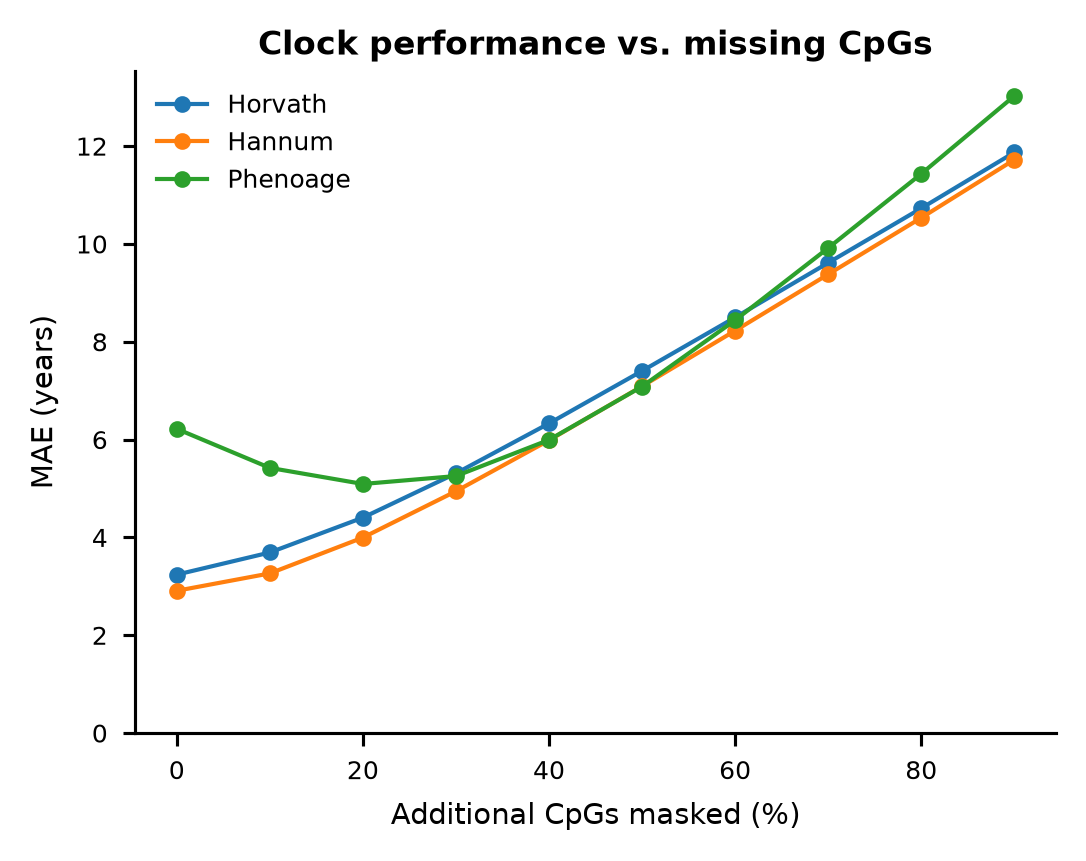

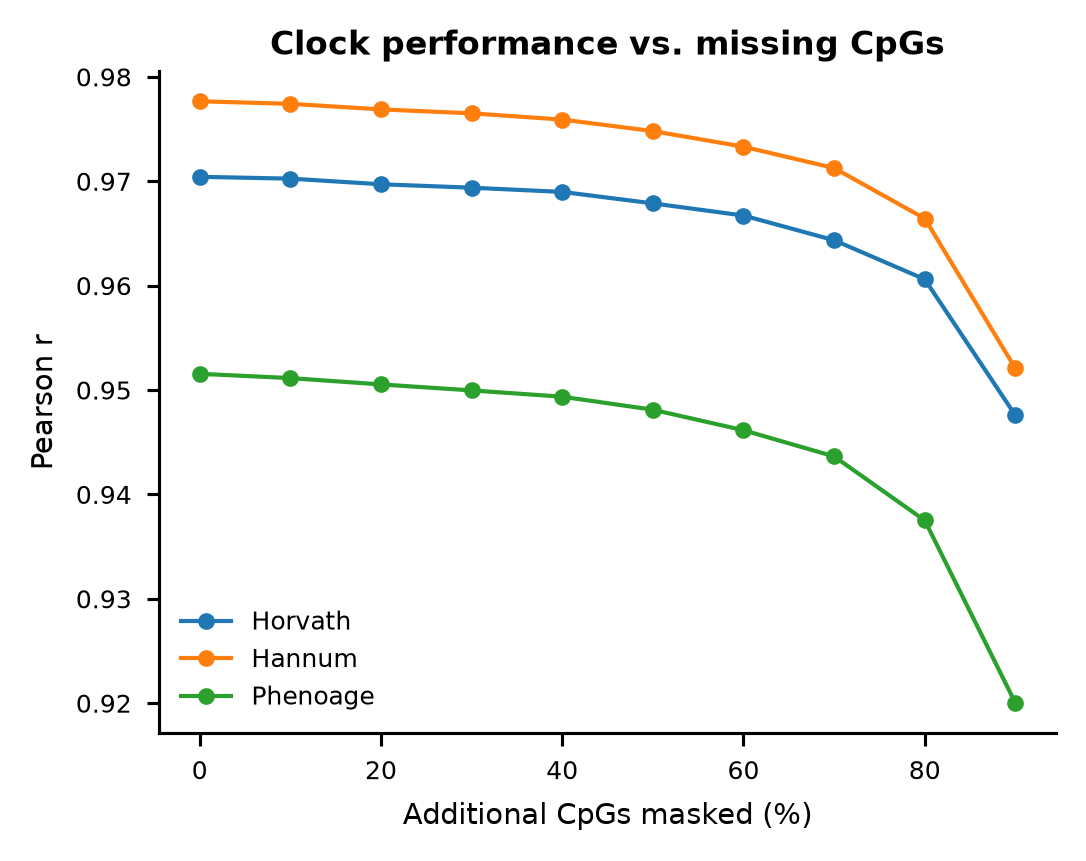

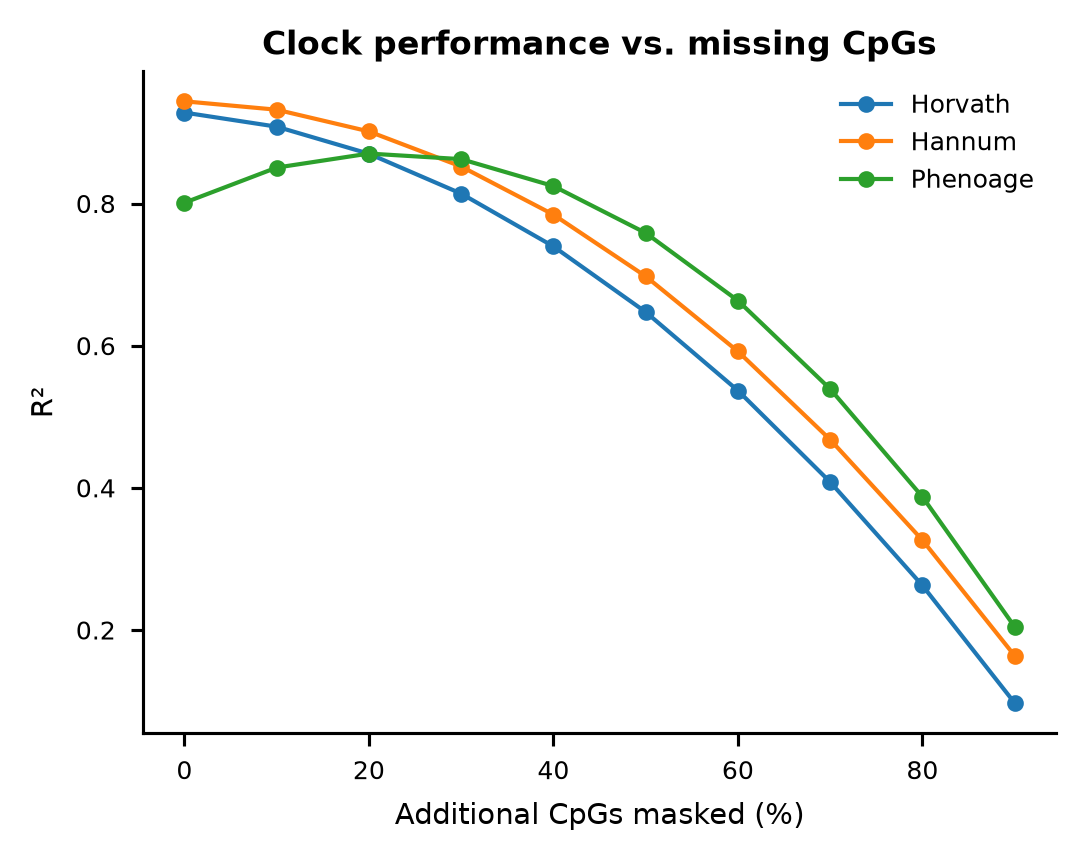

In [17]:
for metric in ("mae", "pearson_r", "r2"):
    fig, ax = eu.plot_missing_fraction_curves(mask_results, metric=metric, x="mask_frac",
                                              clock_names=clock_names)
    fig.savefig(SAVE_DIR / f"masking_curve_{metric}.pdf")
    fig.savefig(SAVE_DIR / f"masking_curve_{metric}.png")
    plt.show()

## Analysis 2 — Systematic removal

The same CpGs are removed from every sample, ordered by `REMOVAL_STRATEGY` across the 78,464 PC clock features. `removal_frac` is the fraction of observed features removed. Metrics are against the original clock ages, with `*_self` columns as in Analysis 1.

In [18]:
ranked_idx, n_eligible = rank_features(REMOVAL_STRATEGY)
print(f"Strategy: {REMOVAL_STRATEGY} | {n_eligible:,} eligible features")
print("First 5 removed:", [FEATURES[i] for i in ranked_idx[:5]])

syst_rows = []
for frac in REMOVAL_FRACTIONS:
    mask, n_removed = mask_systematic(ranked_idx, n_eligible, frac)
    tm    = total_missing(mask)
    preds = baseline_preds if n_removed == 0 else predict_pc_clocks(apply_mask(mask))
    for name, m in score_all(preds).items():
        syst_rows.append(dict(clock=name, removal_frac=frac, n_removed=n_removed,
                              total_missing=tm, n=len(sample_ids), **m))
    del mask
    gc.collect()
    print(f"  frac={frac:.1f} done ({n_removed:,} features removed)")

systematic_results = pd.DataFrame(syst_rows)
systematic_results.to_csv(SYSTEMATIC_CSV)
print(f"Saved -> {SYSTEMATIC_CSV}")
print("MAE vs. original clock ages:")
display(systematic_results.pivot(index="removal_frac", columns="clock", values="mae").round(3))

Strategy: high_variance | 78,425 eligible features
First 5 removed: ['cg11738485', 'cg04131969', 'cg24851651', 'cg05528899', 'cg21139150']
  frac=0.0 done (0 features removed)
  frac=0.1 done (7,842 features removed)
  frac=0.2 done (15,685 features removed)
  frac=0.3 done (23,527 features removed)
  frac=0.4 done (31,370 features removed)
  frac=0.5 done (39,212 features removed)
  frac=0.6 done (47,055 features removed)
  frac=0.7 done (54,897 features removed)
  frac=0.8 done (62,740 features removed)
  frac=0.9 done (70,582 features removed)
Saved -> /work/gr-fe/bryan/EpiHydra/results/pcclocks_results_systematic.csv
MAE vs. original clock ages:


clock,hannum_age,horvath_age,phenoage_age
removal_frac,,,
0.0,2.909,3.239,6.220
0.1,5.620,5.710,6.032
0.2,8.017,8.032,9.361
0.3,9.977,10.123,11.824
0.4,11.219,11.541,13.245
0.5,12.057,12.418,14.025
0.6,12.545,12.794,14.396
0.7,12.763,12.909,14.576
0.8,12.837,12.930,14.609


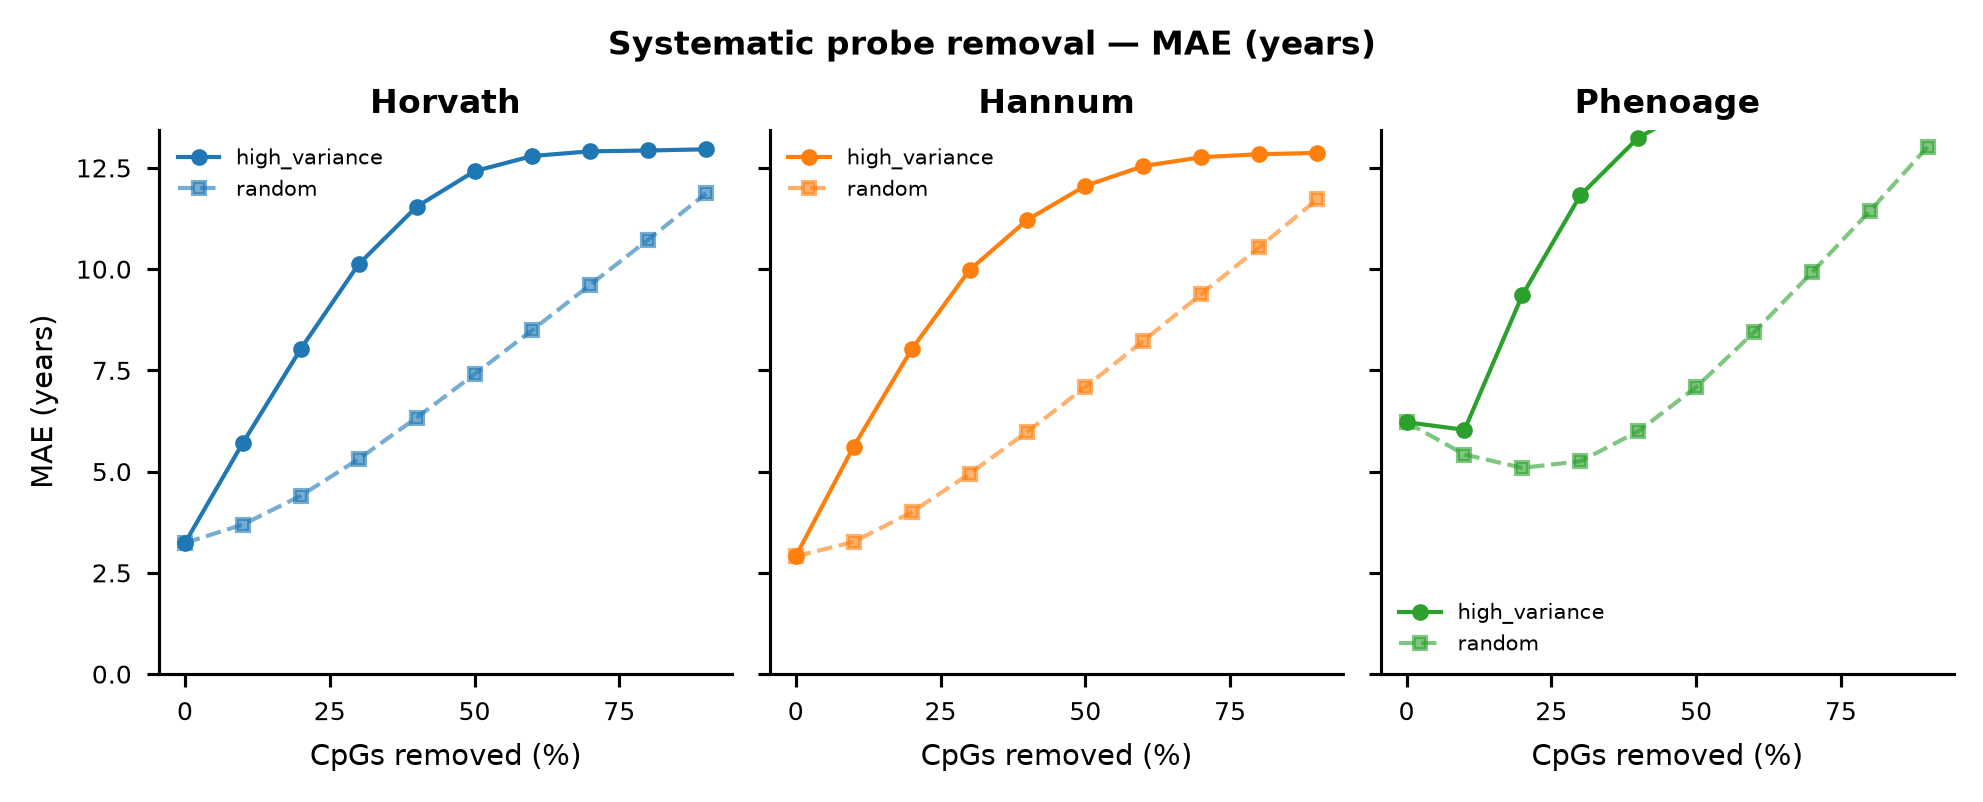

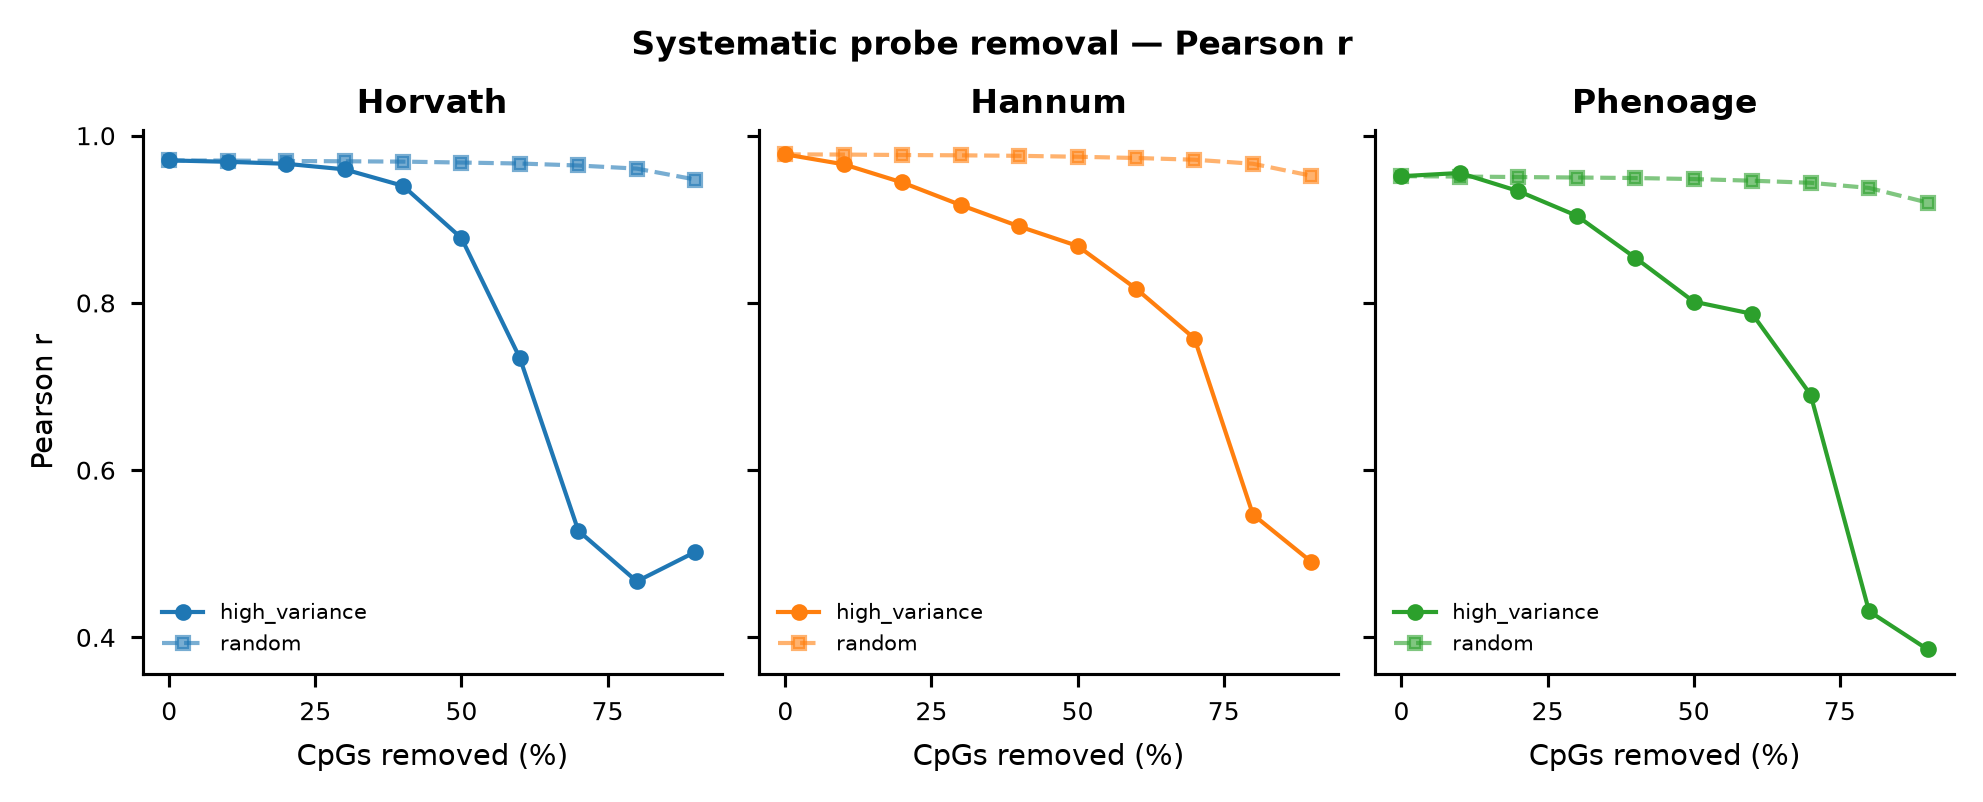

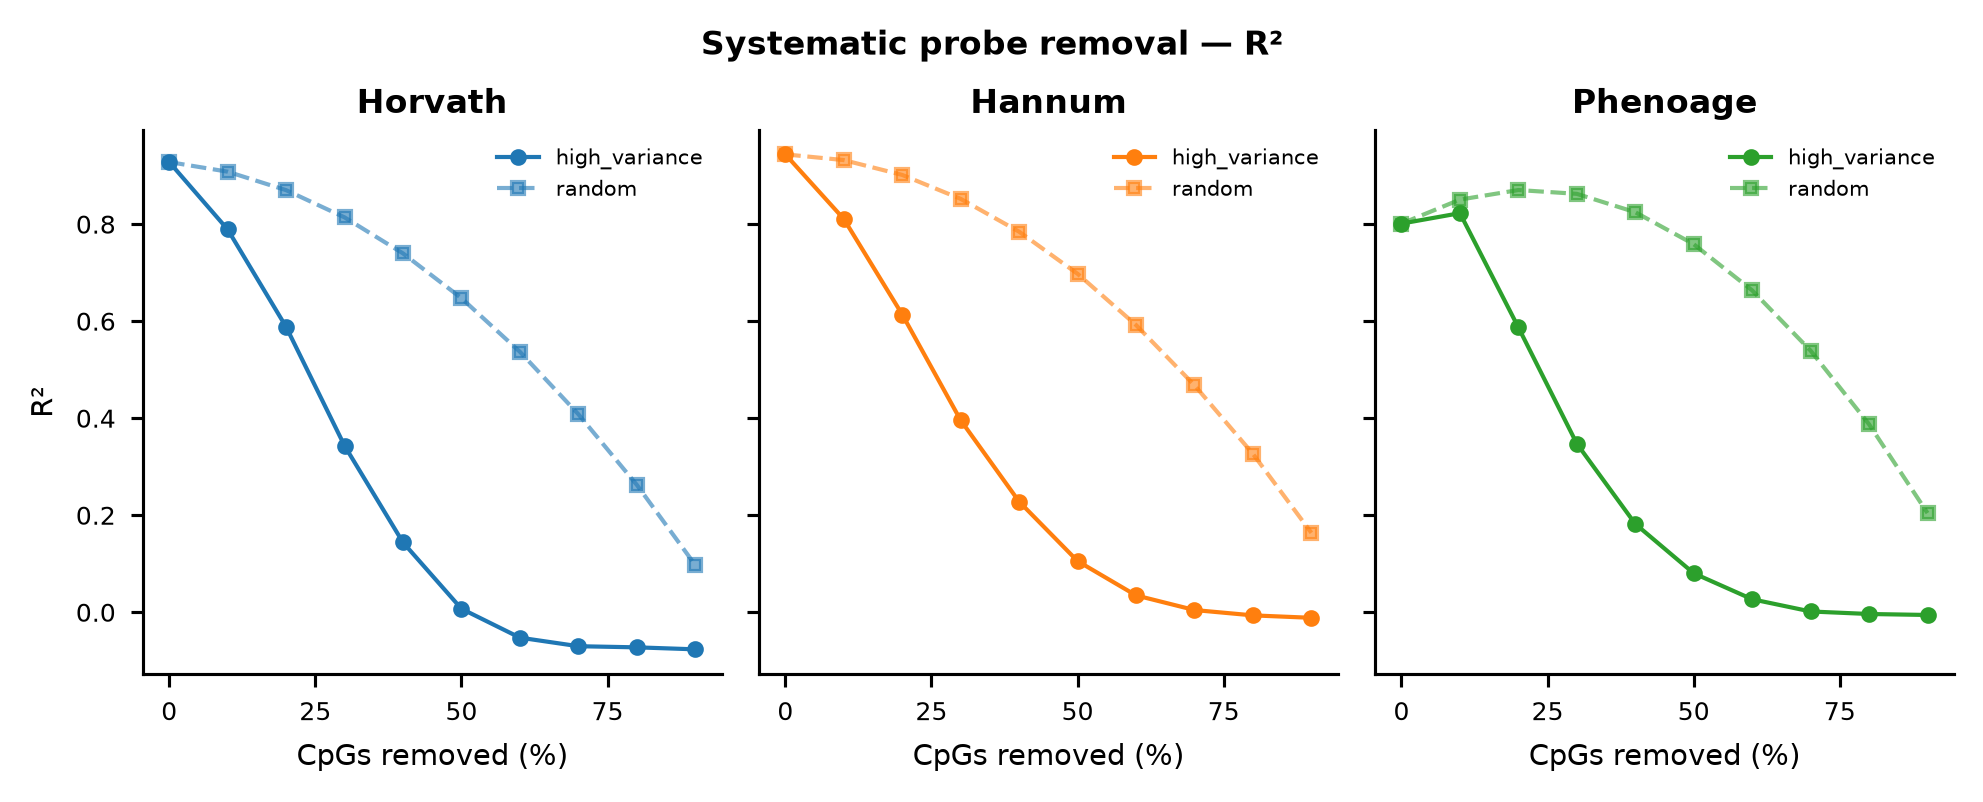

In [19]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_systematic_removal_curves(
        systematic_results,
        random_results = mask_results.rename(columns={"mask_frac": "removal_frac"}),
        metric         = metric,
        clock_names    = clock_names,
        strategy_label = REMOVAL_STRATEGY,
        x              = "removal_frac",
    )
    fig.savefig(SAVE_DIR / f"systematic_removal_{metric}.pdf")
    fig.savefig(SAVE_DIR / f"systematic_removal_{metric}.png")
    plt.show()

## Summary at the heaviest missingness level

All metrics compare masked PC clock predictions with the original clock ages, so the 0% row is the PC clocks' proxy error rather than zero.

In [20]:
worst = max(MASK_FRACTIONS)
zero  = mask_results[mask_results["mask_frac"] == 0.0].set_index("clock")
w_rnd = mask_results[mask_results["mask_frac"] == worst].set_index("clock")
w_sys = systematic_results[systematic_results["removal_frac"] == worst].set_index("clock")

summary = zero[["mae", "pearson_r", "r2"]].add_prefix("zero_mask_")
for m in ("mae", "pearson_r", "r2"):
    summary[f"rand_{m}"]       = w_rnd[m]
    summary[f"syst_{m}"]       = w_sys[m]
    summary[f"delta_rand_{m}"] = summary[f"rand_{m}"] - summary[f"zero_mask_{m}"]
    summary[f"delta_syst_{m}"] = summary[f"syst_{m}"] - summary[f"zero_mask_{m}"]

print(f"Worst fraction: {worst:.0%} | Removal strategy: {REMOVAL_STRATEGY}")
print("All metrics: masked PC clock prediction vs. original clock age (0% missing)")
display(summary.round(3))

Worst fraction: 90% | Removal strategy: high_variance
All metrics: masked PC clock prediction vs. original clock age (0% missing)


,zero_mask_mae,zero_mask_pearson_r,zero_mask_r2,rand_mae,syst_mae,delta_rand_mae,delta_syst_mae,rand_pearson_r,syst_pearson_r,delta_rand_pearson_r,delta_syst_pearson_r,rand_r2,syst_r2,delta_rand_r2,delta_syst_r2
clock,,,,,,,,,,,,,,,
horvath_age,3.239,0.970,0.928,11.872,12.959,8.633,9.720,0.948,0.502,-0.023,-0.468,0.097,-0.076,-0.831,-1.004
hannum_age,2.909,0.978,0.944,11.722,12.868,8.813,9.959,0.952,0.490,-0.026,-0.487,0.164,-0.011,-0.780,-0.955
phenoage_age,6.220,0.952,0.801,13.026,14.622,6.806,8.402,0.920,0.386,-0.032,-0.566,0.204,-0.006,-0.597,-0.807
